# EDA: Energy-Charts, Swiss solar generation

**What the data is:** hourly *public net electricity generation* in Switzerland per energy source, published by Energy-Charts (Fraunhofer ISE). We use the column `Solar`: our target variable.

| | |
|---|---|
| Website | https://www.energy-charts.info/charts/power/chart.htm?l=en&c=CH |
| API (documentation) | https://api.energy-charts.info |
| Request used | `https://api.energy-charts.info/public_power?country=ch&start=2025-01-01T00:00Z&end=2026-01-01T00:00Z` (one request per year) |
| Method for Swiss solar | extrapolated from measured reference plants and scaled to the official SFOE totals: https://www.energy-charts.info/explanations.html?l=en&c=CH |
| Licence | CC BY 4.0, attribution "energy-charts.info" |
| Files | `data/public_power_ch_2015.json` … `public_power_ch_2026.json`, downloaded 16.10.2026; not versioned, get them with `download_data.py` |
| One row | one hour in Switzerland; values are mean power in MW (the `Renewable share` columns are in %) |
| Time span and resolution | 1 Jan 2015 to 16 Oct 2026, hourly |
| Time zone | delivered in UTC; **we work in Central European Time without clock changes (fixed CET = UTC+1) throughout the project** |

**How this notebook works:** every section starts with a **question**, then the code, a chart where useful, and a note **Finding → Consequence**.
It follows the course EDA guide: *Step 1* validity (Q1–Q9), *Step 2* patterns and suitability (Q10–Q13). *Step 3*, the relationship with the weather, follows in the combined notebook.
*Prepared with AI assistance (Claude); findings to be questioned and checked by us.*

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data")
FIG = Path("../../figures/eda")   # plots for the README, as required by the course guide
FIG.mkdir(parents=True, exist_ok=True)
TZ = "Etc/GMT-1"   # fixed CET = UTC+1, no clock changes (the minus sign is correct for this name)
pd.set_option("display.max_columns", None)   # show all columns side by side
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"


def save(fig, name):
    fig.savefig(FIG / f"energy_charts_{name}.png", dpi=160, bbox_inches="tight")

# Step 1: Is the data valid?

## Q1: What does one raw file look like?

In [2]:
raw = json.loads((DATA / "public_power_ch_2025.json").read_text(encoding="utf-8"))
print("Keys:", list(raw.keys()))
print("First time stamps (unix seconds):", raw["unix_seconds"][:3])
print("Production types:")
for p in raw["production_types"]:
    print(f"  {p['name']:<35} {len(p['data'])} values, first: {p['data'][0]}")

Keys: ['unix_seconds', 'production_types', 'deprecated']
First time stamps (unix seconds): [1735689600, 1735693200, 1735696800]
Production types:
  Cross border electricity trading    8761 values, first: 3136.6
  Nuclear                             8761 values, first: 2960.5
  Hydro Run-of-River                  8761 values, first: 920.9
  Hydro water reservoir               8761 values, first: 745.2
  Hydro pumped storage                8761 values, first: 118.5
  Others                              8761 values, first: 453.7
  Wind onshore                        8761 values, first: 47.4
  Solar                               8761 values, first: 0.0
  Load                                8761 values, first: 8432.4
  Residual load                       8761 values, first: 8385.0
  Renewable share of load             8761 values, first: 20.3
  Renewable share of generation       8761 values, first: 33.4


> **Finding:** one JSON per year with `unix_seconds` (seconds since 1970, **UTC**) and one list of values per production type (among them `Solar`). The i-th value of each list belongs to the i-th time stamp.
> **Consequence:** convert the time stamps to CET and make one column per production type.

## Q2: Load all years into one pandas table. Which columns and data types do we have?

In [3]:
def load_year(path):
    d = json.loads(path.read_text(encoding="utf-8"))
    index = pd.to_datetime(d["unix_seconds"], unit="s", utc=True).tz_convert(TZ)
    return pd.DataFrame({p["name"]: p["data"] for p in d["production_types"]}, index=index)

frames = [load_year(f) for f in sorted(DATA.glob("public_power_ch_*.json"))]
df = pd.concat(frames)
print("Rows before removing duplicates:", len(df), "| duplicated time stamps:", df.index.duplicated().sum())
df = df[~df.index.duplicated(keep="first")].sort_index()
df.index.name = "time_cet"
df.head()

Rows before removing duplicates: 103368 | duplicated time stamps: 11


,Cross border electricity trading,Fossil gas,Others,Wind onshore,Solar,Load,Residual load,Renewable share of load,Renewable share of generation,Nuclear,Hydro water reservoir,Hydro pumped storage,Hydro Run-of-River
time_cet,,,,,,,,,,,,,
2015-01-01 01:00:00+01:00,2965.8,NaN,359.2,13.6,0.0,7633.0,7619.4,0.2,3.6,NaN,NaN,NaN,NaN
2015-01-01 02:00:00+01:00,2711.1,NaN,359.2,14.0,0.0,7653.6,7639.6,0.2,3.8,NaN,NaN,NaN,NaN
2015-01-01 03:00:00+01:00,3301.5,NaN,359.2,12.8,0.0,7397.0,7384.2,0.2,3.4,NaN,NaN,NaN,NaN
2015-01-01 04:00:00+01:00,3081.1,NaN,359.2,13.7,0.0,7340.4,7326.7,0.2,3.7,NaN,NaN,NaN,NaN
2015-01-01 05:00:00+01:00,3229.8,NaN,359.2,10.1,0.1,7015.0,7004.8,0.1,2.8,NaN,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 103357 entries, 2015-01-01 01:00:00+01:00 to 2026-10-16 13:00:00+01:00
Data columns (total 13 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   Cross border electricity trading  103357 non-null  float64
 1   Fossil gas                        3343 non-null    float64
 2   Others                            103357 non-null  float64
 3   Wind onshore                      103350 non-null  float64
 4   Solar                             103350 non-null  float64
 5   Load                              103357 non-null  float64
 6   Residual load                     103357 non-null  float64
 7   Renewable share of load           103357 non-null  float64
 8   Renewable share of generation     103357 non-null  float64
 9   Nuclear                           99103 non-null   float64
 10  Hydro water reservoir             99015 non-null   float64
 11  Hydro pumped stor

In [5]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Cross border electricity trading,103357.0,28.7,2286.3,-8812.9,-1376.1,320.8,1716.9,6129.1
Fossil gas,3343.0,7.4,38.2,0.0,0.0,0.0,0.0,329.1
Others,103357.0,412.1,25.9,337.5,404.9,411.2,426.3,487.5
Wind onshore,103350.0,15.6,37.3,0.0,4.4,10.3,22.1,11000.0
Solar,103350.0,435.0,897.4,0.0,0.0,5.5,456.3,6630.1
Load,103357.0,7555.5,1090.2,3065.8,6769.0,7536.6,8272.8,12234.1
Residual load,103357.0,7104.9,1282.4,-4315.1,6300.5,7084.3,7932.7,11382.5
Renewable share of load,103357.0,55.4,30.4,0.0,33.1,52.2,75.2,222.0
Renewable share of generation,103357.0,55.1,17.7,0.0,45.0,57.4,68.1,92.6
Nuclear,99103.0,2438.5,679.9,0.0,1796.8,2789.3,2956.4,3333.1


> **Finding:** 13 numeric columns, hourly from 2015 to mid-October 2026. Each yearly file also contains the first hour of the next year, which gives **11 duplicated time stamps**. `Solar` is never negative.
> **Consequence:** drop the duplicates (done above) and focus on `Solar`.

## Q3: Is every hour present? Where are values missing, and why?

Expected hours: 103357 | present: 103357 | missing time stamps: 0
Empty values (NaN) in Solar: 7


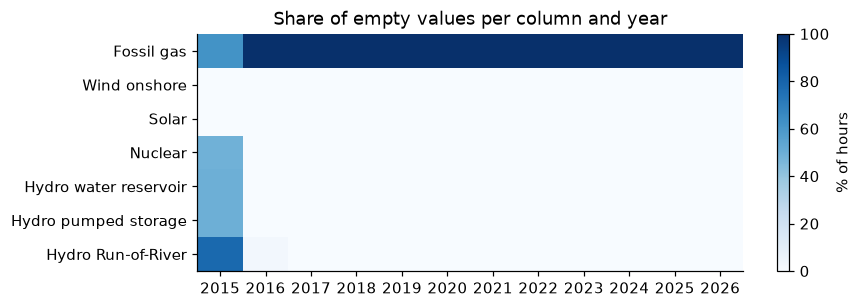

First value per column:
Nuclear                 2015-04-20 23:00:00+01:00
Hydro water reservoir   2015-06-30 23:00:00+01:00
Hydro Run-of-River      2015-10-12 23:00:00+01:00
Solar                   2015-01-01 01:00:00+01:00


time_cet
2017-10-27 22:00:00+01:00    0.0
2017-10-27 23:00:00+01:00    0.0
2017-10-28 00:00:00+01:00    0.0
2017-10-28 01:00:00+01:00    NaN
2017-10-28 02:00:00+01:00    NaN
2017-10-28 03:00:00+01:00    NaN
2017-10-28 04:00:00+01:00    NaN
2017-10-28 05:00:00+01:00    NaN
2017-10-28 06:00:00+01:00    NaN
2017-10-28 07:00:00+01:00    NaN
2017-10-28 08:00:00+01:00    0.0
2017-10-28 09:00:00+01:00    0.0
2017-10-28 10:00:00+01:00    0.0
2017-10-28 11:00:00+01:00    0.0
2017-10-28 12:00:00+01:00    0.0
Name: Solar, dtype: float64

In [6]:
solar = df["Solar"]
expected = pd.date_range(solar.index.min(), solar.index.max(), freq="h")
print("Expected hours:", len(expected), "| present:", len(solar), "| missing time stamps:", len(expected.difference(solar.index)))
print("Empty values (NaN) in Solar:", solar.isna().sum())

missing = df.isna().groupby(df.index.year).mean().loc[:, lambda t: t.sum() > 0] * 100
fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(missing.T, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(missing)), missing.index)
ax.set_yticks(range(missing.shape[1]), missing.columns)
ax.set_title("Share of empty values per column and year")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of hours")
save(fig, "missing_per_year")
plt.show()
print("First value per column:")
print(df[["Nuclear", "Hydro water reservoir", "Hydro Run-of-River", "Solar"]].apply(lambda c: c.first_valid_index()).to_string())
solar.loc["2017-10-27 22:00":"2017-10-28 12:00"]

> **Finding:** no hour is missing in the time axis. The empty values are **systematic, not random**:
> - In 2015 several sources had no continuous data yet (`Nuclear` and two hydro columns from about July, `Hydro Run-of-River` from October, with another gap in November 2016). `Fossil gas` exists only in the 2015 file.
> - `Solar` has 7 empty hours on 28.10.2017 (01:00–07:00 CET), and the rest of that day is exactly 0. **The whole day is a data gap.**
>
> **Consequence:** these gaps are not random, so we do not fill them. 28.10.2017 counts as missing (see Q5). A complete time axis does **not** mean the values are correct.

## Q4: Is every year complete? Compare the annual sums with the official statistics

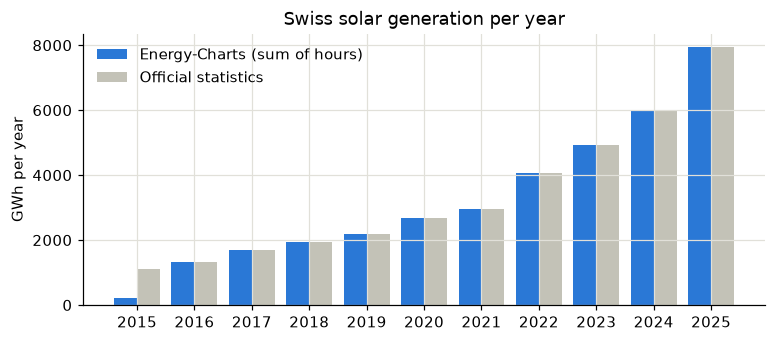

,Energy-Charts_GWh,official_GWh,difference_GWh
2015,214.0,1119,-905.0
2016,1334.0,1334,0.0
2017,1683.0,1683,0.0
2018,1945.0,1945,0.0
2019,2178.0,2178,0.0
2020,2692.0,2692,0.0
2021,2964.0,2964,0.0
2022,4067.0,4067,0.0
2023,4914.0,4914,0.0
2024,5961.0,5961,0.0


In [7]:
annual = (solar.groupby(solar.index.year).sum() / 1000).round(0)   # MWh -> GWh
# official Swiss PV production in GWh: Swissolar/SFOE, Statistik Sonnenenergie 2025, p. 7
official = pd.Series({2015: 1119, 2016: 1334, 2017: 1683, 2018: 1945, 2019: 2178, 2020: 2692,
                      2021: 2964, 2022: 4067, 2023: 4914, 2024: 5961, 2025: 7948})
compare = pd.DataFrame({"Energy-Charts_GWh": annual.loc[2015:2025], "official_GWh": official})
compare["difference_GWh"] = compare["Energy-Charts_GWh"] - compare["official_GWh"]

fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(compare))
ax.bar(x - 0.2, compare["Energy-Charts_GWh"], width=0.4, color=BLUE, label="Energy-Charts (sum of hours)")
ax.bar(x + 0.2, compare["official_GWh"], width=0.4, color=GREY, label="Official statistics")
ax.set_xticks(x, compare.index)
ax.set_ylabel("GWh per year")
ax.set_title("Swiss solar generation per year")
ax.legend(frameon=False)
save(fig, "annual_vs_official")
plt.show()
compare

> **Finding:** **2015 is far too low**: every month has values, but the year reaches only 19 % of the official total (214 instead of 1,119 GWh). From 2016 to 2025 the annual sums are **identical** to the official statistics, so Energy-Charts scales its curve to the official totals.
> **Consequence:** drop 2015. The annual level can be trusted; the *hourly shape* is an extrapolation, which we mention as a limitation.

## Q5: Are there zeros that are really missing values?

In [8]:
daily = solar.resample("D").sum() / 1000                          # GWh per day
typical = daily.rolling(15, center=True, min_periods=7).median()  # typical value of the surrounding days
suspicious = daily[(daily < 0.10 * typical) & (daily.index.year >= 2016)]
print("Suspicious days (less than 10 % of the surrounding days):", len(suspicious))
print(suspicious.groupby(suspicious.index.year).size().to_string())

# Gaps come in runs: how long are the stretches of exactly 0? A normal night is shorter than 24 hours.
is_zero = solar.fillna(0) == 0
run_id = (is_zero != is_zero.shift()).cumsum()
zero_hours = solar[is_zero]
runs = pd.DataFrame({"start": zero_hours.index.to_series().groupby(run_id[is_zero]).first(),
                     "hours": zero_hours.groupby(run_id[is_zero]).size()})
print("\nStretches of 24 hours or more with solar = 0, since 2016:")
print(runs[(runs["hours"] >= 24) & (runs["start"].dt.year >= 2016)].to_string(index=False))
suspicious.round(2).to_frame("GWh")

Suspicious days (less than 10 % of the surrounding days): 30
time_cet
2016     2
2017     3
2018    13
2019    11
2024     1

Stretches of 24 hours or more with solar = 0, since 2016:
                    start  hours
2017-10-27 21:00:00+01:00     32
2018-02-19 18:00:00+01:00    107
2018-02-24 22:00:00+01:00     55


,GWh
time_cet,
2016-06-15 00:00:00+01:00,0.18
2016-09-23 00:00:00+01:00,0.01
2017-10-28 00:00:00+01:00,0.00
2017-12-10 00:00:00+01:00,0.05
2017-12-18 00:00:00+01:00,0.04
2018-02-15 00:00:00+01:00,0.05
2018-02-20 00:00:00+01:00,0.00
2018-02-21 00:00:00+01:00,0.00
2018-02-22 00:00:00+01:00,0.00


Same periods side by side: 2018 (left) vs. 2019 (right). Orange background = suspicious day.

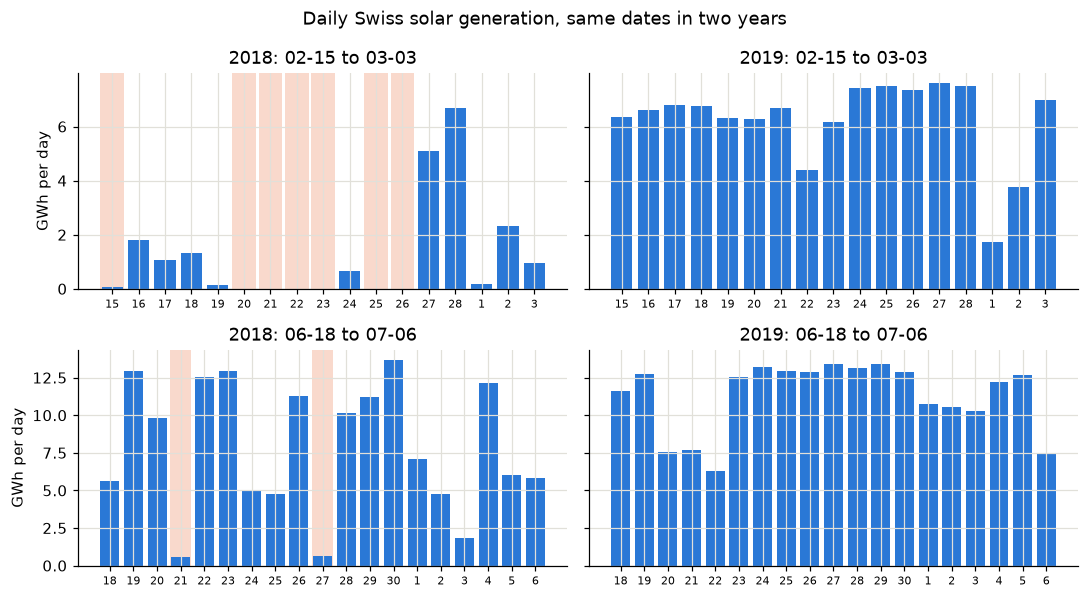

In [9]:
periods = [("02-15", "03-03"), ("06-18", "07-06")]
fig, axes = plt.subplots(2, 2, figsize=(10, 5.5), sharey="row")
for row, (a, b) in enumerate(periods):
    for col, year in enumerate([2018, 2019]):
        d = daily.loc[f"{year}-{a}":f"{year}-{b}"]
        ax = axes[row, col]
        x = np.arange(len(d))
        ax.bar(x, d.values, color=BLUE)
        for i, t in enumerate(d.index):
            if t in suspicious.index:   # shade the day, so a zero bar is still visible
                ax.axvspan(i - 0.45, i + 0.45, color=ORANGE, alpha=0.25, linewidth=0, zorder=0)
        ax.set_xticks(x, d.index.day)
        ax.set_title(f"{year}: {a} to {b}")
        ax.tick_params(axis="x", labelsize=7)
    axes[row, 0].set_ylabel("GWh per day")
fig.suptitle("Daily Swiss solar generation, same dates in two years")
plt.tight_layout()
save(fig, "suspicious_days_2018_vs_2019")
plt.show()

> **Finding:** 30 suspicious days since 2016, most of them in **2018** (13) and **2019** (11, mainly December). In February 2018 six days are **exactly 0** for the whole of Switzerland, in two long stretches of 107 and 55 hours; on 21 and 27 June 2018 only 0.6 GWh instead of 10–13 GWh. A whole country with zero solar power during daytime is physically impossible.
> **Consequence:** treat suspicious days as **missing (NaN), not as zero**. The next section checks them against the measured sun and decides what to do with 2018.

### Q5b: Was the sun shining on the suspicious days? And can we rescue 2018?

We compare with the measured radiation (mean of the four Lucerne stations, data from the MeteoSwiss notebook in `../meteoswiss/data`; run its `download_data.py` first).

Suspicious days with at least 40 % of the typical sun: 27 of 30
Snow depth in Luzern, 21-23.11.2024 (cm): [0.0, 36.0, 25.0]


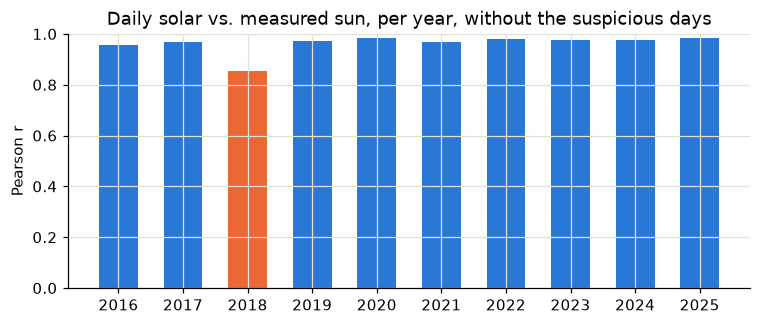

      r, all days  r, without suspicious days
2016        0.948                       0.956
2017        0.969                       0.970
2018        0.819                       0.855
2019        0.962                       0.973
2020        0.985                       0.985
2021        0.969                       0.969
2022        0.982                       0.982
2023        0.978                       0.978
2024        0.976                       0.976
2025        0.985                       0.985


,solar_GWh,typical_solar_GWh,sun_vs_typical
time_cet,,,
2016-06-15 00:00:00+01:00,0.18,4.5,1.02
2016-09-23 00:00:00+01:00,0.01,4.4,1.06
2017-10-28 00:00:00+01:00,0.00,3.2,1.14
2017-12-10 00:00:00+01:00,0.05,0.5,0.47
2017-12-18 00:00:00+01:00,0.04,0.6,0.77
2018-02-15 00:00:00+01:00,0.05,0.9,0.64
2018-02-20 00:00:00+01:00,0.00,0.1,1.00
2018-02-21 00:00:00+01:00,0.00,0.1,0.88
2018-02-22 00:00:00+01:00,0.00,0.1,0.33


In [10]:
def load_radiation(abbr):
    files = sorted(Path("../meteoswiss/data").glob(f"ogd-smn_{abbr}_h_*.csv"))
    d = pd.concat(pd.read_csv(f, sep=";", encoding="cp1252", usecols=["reference_timestamp", "gre000h0"]) for f in files)
    # MeteoSwiss stamps the end of the hour, so -1 h gives the start of the hour, like Energy-Charts
    d["time"] = pd.to_datetime(d["reference_timestamp"], format="%d.%m.%Y %H:%M", utc=True).dt.tz_convert(TZ) - pd.Timedelta(hours=1)
    return d.drop_duplicates("time", keep="last").set_index("time")["gre000h0"]

sun = pd.concat([load_radiation(a) for a in ["luz", "moa", "spf", "ego"]], axis=1).mean(axis=1).resample("D").sum(min_count=20) / 1000
typical_sun = sun.rolling(15, center=True, min_periods=7).median()
check = pd.DataFrame({"solar_GWh": suspicious.round(2), "typical_solar_GWh": typical.reindex(suspicious.index).round(1),
                      "sun_vs_typical": (sun / typical_sun).reindex(suspicious.index).round(2)})
print("Suspicious days with at least 40 % of the typical sun:", (check["sun_vs_typical"] >= 0.4).sum(), "of", len(check))

# Snow depth in Luzern (MeteoSwiss delivers it for this station only from late 2023)
snow_files = sorted(Path("../meteoswiss/data").glob("ogd-smn_luz_d_*.csv"))
snow = pd.concat(pd.read_csv(f, sep=";", encoding="cp1252", usecols=["reference_timestamp", "htoautd0"]) for f in snow_files)
snow["day"] = pd.to_datetime(snow["reference_timestamp"], format="%d.%m.%Y %H:%M")
snow = snow.drop_duplicates("day", keep="last").set_index("day")["htoautd0"]
print("Snow depth in Luzern, 21-23.11.2024 (cm):", snow.loc["2024-11-21":"2024-11-23"].tolist())

both = pd.DataFrame({"solar": daily, "sun": sun}).dropna().loc["2016":"2025"]
without = both.drop(suspicious.index, errors="ignore")
per_year = pd.DataFrame({"r, all days": both.groupby(both.index.year).apply(lambda t: t["solar"].corr(t["sun"])),
                         "r, without suspicious days": without.groupby(without.index.year).apply(lambda t: t["solar"].corr(t["sun"]))}).round(3)

fig, ax = plt.subplots(figsize=(8, 3))
years = per_year.index
ax.bar(years, per_year["r, without suspicious days"], width=0.6, color=[ORANGE if y == 2018 else BLUE for y in years])
ax.set_xticks(years)
ax.set_ylim(0, 1)
ax.set_ylabel("Pearson r")
ax.set_title("Daily solar vs. measured sun, per year, without the suspicious days")
save(fig, "correlation_per_year")
plt.show()
print(per_year.to_string())
check

> **Finding:** on 27 of the 30 suspicious days the sun was shining (at least 40 % of the typical value), so **nearly all are data errors, not dark days**. Three days were dark, but this does not explain values near zero. **22.11.2024 is probably real:** 36 cm of snow in Luzern, so snow on the panels explains the low output although the sun shone; it stays in the data. For earlier days we cannot test this, because the snow data of this station only start in late 2023.
> Even **without** its suspicious days, 2018 fits the weather far worse (Pearson r = 0.855, daily solar vs. sun) than every other year (0.956 or higher): many other days of 2018 are wrong too.
>
> **Decision: we leave out 2018 completely and do not approximate it from the radiation.**
> 1. **Replacing the flagged days is not enough.** Nearly the whole year would have to be replaced.
> 2. **It would be circular.** The model should learn solar generation from the weather. Solar values calculated from the weather would inflate the correlation artificially.
> 3. **We do not need it.** 2019–2024 gives six training years, and 2025 is the test year.
>
> The same holds for the suspicious days in 2019: they become **missing values and are not interpolated** (SARIMAX in statsmodels can handle missing values). 22.11.2024 is kept.

## Q6: Time zone. Why fixed CET and not the clock time with its changes?

Clock time: days in 2025 that do not have 24 hours:
2025-03-30    23
2025-10-26    25
Clock time: duplicated time stamps once the time zone is removed: 11
Fixed CET: days in 2025 that do not have 24 hours: 0 | duplicated time stamps: 0
Energy-weighted mean hour, CET: 11.97
Clock-change days: mean hour minus neighbouring days: {'2019-03-31': np.float64(-0.93), '2019-10-27': np.float64(0.98), '2020-03-29': np.float64(-1.3), '2020-10-25': np.float64(-0.48), '2021-03-28': np.float64(-0.17), '2021-10-31': np.float64(-0.51), '2022-03-27': np.float64(-0.02), '2022-10-30': np.float64(0.02), '2023-03-26': np.float64(-0.02), '2023-10-29': np.float64(0.43), '2024-03-31': np.float64(-0.29), '2024-10-27': np.float64(0.13), '2025-03-30': np.float64(-0.56), '2025-10-26': np.float64(0.33)}


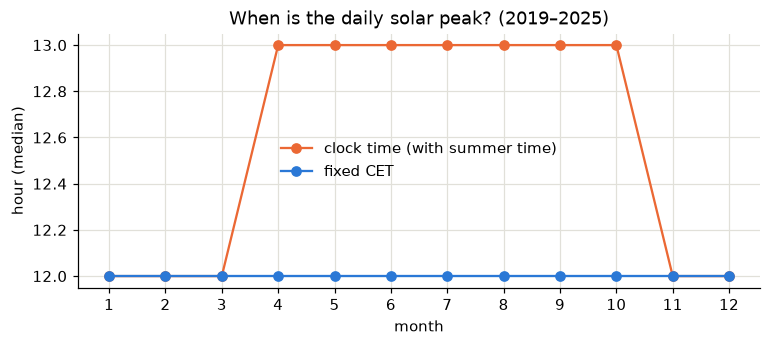

In [11]:
clock = solar.tz_convert("Europe/Zurich")     # clock time in Switzerland, with summer time, for comparison
per_day = clock.loc["2025"].groupby(clock.loc["2025"].index.date).size()
print("Clock time: days in 2025 that do not have 24 hours:")
print(per_day[per_day != 24].to_string())
print("Clock time: duplicated time stamps once the time zone is removed:", clock.index.tz_localize(None).duplicated().sum())
print("Fixed CET: days in 2025 that do not have 24 hours:", (solar.loc["2025"].groupby(solar.loc["2025"].index.date).size() != 24).sum(),
      "| duplicated time stamps:", solar.index.tz_localize(None).duplicated().sum())

period = solar.loc["2019":"2025"]
# Does a stamp mark the start of the hour? Solar noon in Switzerland is at about 12.45 CET (8.3 degrees east).
# The energy-weighted mean stamp would be about 11.95 for the start of the hour and 12.95 for the end.
weighted_hour = lambda x: (x.index.hour * x).sum() / x.sum()
print("Energy-weighted mean hour, CET:", round(weighted_hour(period.dropna()), 2))

# Are the clock-change days themselves aligned? Compare with the day before and the day after.
changes = ["2019-03-31", "2019-10-27", "2020-03-29", "2020-10-25", "2021-03-28", "2021-10-31", "2022-03-27",
           "2022-10-30", "2023-03-26", "2023-10-29", "2024-03-31", "2024-10-27", "2025-03-30", "2025-10-26"]
shift = {}
for day in changes:
    t = pd.Timestamp(day)
    shift[day] = round(weighted_hour(solar.loc[day]) - np.mean([weighted_hour(solar.loc[str((t + pd.Timedelta(days=k)).date())]) for k in (-1, 1)]), 2)
print("Clock-change days: mean hour minus neighbouring days:", shift)

peak = pd.to_datetime(period.groupby(period.index.date).idxmax().values, utc=True)
peak_hours = pd.DataFrame({"month": peak.tz_convert(TZ).month, "CET": peak.tz_convert(TZ).hour,
                           "clock": peak.tz_convert("Europe/Zurich").hour})
monthly = peak_hours.groupby("month").median()
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(monthly.index, monthly["clock"], color=ORANGE, marker="o", label="clock time (with summer time)")
ax.plot(monthly.index, monthly["CET"], color=BLUE, marker="o", label="fixed CET")
ax.set_xticks(range(1, 13))
ax.set_xlabel("month")
ax.set_ylabel("hour (median)")
ax.set_title("When is the daily solar peak? (2019–2025)")
ax.legend(frameon=False)
save(fig, "peak_hour_time_zone")
plt.show()

> **Finding:** with clock time there is one day with **23 hours** (March) and one with **25 hours** (October), the solar peak jumps from 12:00 to 13:00 in summer, and without the time zone one hour per year is duplicated. In fixed CET **every day has 24 hours** and the peak stays at 12:00 all year, as the sun does. The energy-weighted mean hour of 11.97 confirms that Energy-Charts stamps the **start** of the hour. On both clock-change days of 2019 the curve itself looks shifted by about 1 hour; in later years the differences are smaller and may simply be weather. We keep these few days.
> **Consequence:** work in **fixed CET (UTC+1)** in the whole project, which is European time without the jumps. In summer CET is one hour behind the clock (13:00 on the clock = 12:00 CET); the dashboard can show clock time if needed. MeteoSwiss also delivers UTC and stamps the *end* of each hour, so it needs an extra shift by −1 h (see the MeteoSwiss notebook).

## Q7: Are there impossible values, like solar power at night?

Negative values: 0
Night hours (22:00-03:59 CET) with more than 1 MW:
time_cet
2018-09-11 03:00:00+01:00      1.3
2022-03-12 00:00:00+01:00      3.4
2022-09-19 23:00:00+01:00    415.1
2022-09-20 23:00:00+01:00    415.6
2026-06-18 22:00:00+01:00      2.3
2026-06-20 22:00:00+01:00      2.4
2026-06-24 22:00:00+01:00      2.4
2026-06-25 22:00:00+01:00      2.3
2026-06-26 22:00:00+01:00      2.4
2026-06-27 22:00:00+01:00      4.8
Sun in Lucerne on 19 and 20.09.2021 (kWh/m²): [0.75, 1.7]


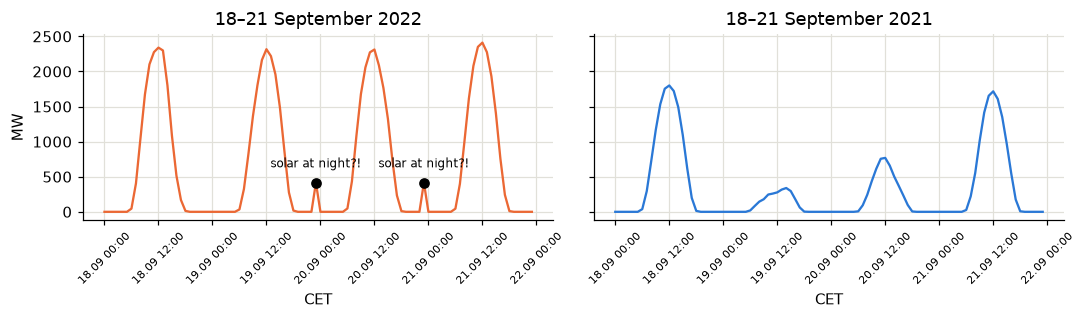

In [12]:
night = solar[solar.index.hour.isin([22, 23, 0, 1, 2, 3])]   # 04:00 CET in June is already dawn
print("Negative values:", (solar < 0).sum())
print("Night hours (22:00-03:59 CET) with more than 1 MW:")
print(night[night > 1].to_string())

spikes = night.loc["2022-09-18":"2022-09-21"]
spikes = spikes[spikes > 100]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, year in zip(axes, [2022, 2021]):
    s = solar.loc[f"{year}-09-18":f"{year}-09-21"]
    ax.plot(s.index, s.values, color=ORANGE if year == 2022 else BLUE)
    ax.set_title(f"18–21 September {year}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M", tz=TZ))
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    ax.set_xlabel("CET")
axes[0].scatter(spikes.index, spikes.values, color="black", zorder=3)
for t, v in spikes.items():
    axes[0].annotate("solar at night?!", (t, v), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8)
axes[0].set_ylabel("MW")
plt.tight_layout()
save(fig, "night_values_2022_vs_2021")
print("Sun in Lucerne on 19 and 20.09.2021 (kWh/m²):", sun.loc["2021-09-19":"2021-09-20"].round(2).tolist())
plt.show()

> **Finding:** no negative values. At 23:00 CET on 19 and 20 September 2022 (midnight on the clock) Energy-Charts reports **415 MW** of solar power. The same dates in 2021 show nothing like this (the low days 19 and 20.09.2021 are cloudy weather: little sun in Lucerne too). All other values in this night window are tiny, at most 4.8 MW. Outside this fixed window small values also appear just after sunset (separate check by sun position: about 1,000 hours in 2019–2025, at most about 20 MW, together 0.004 % of the energy).
> **Consequence:** set the two 415 MW values to NaN. The tiny values are negligible and stay.

## Q8: Did a sensor get stuck? Are there flat lines?

In [13]:
def flat_runs(s):
    # stretches where the value stays exactly the same from one hour to the next
    run = (s != s.shift()).cumsum()
    return pd.DataFrame({"start": s.index.to_series().groupby(run).first(), "value": s.groupby(run).first(),
                         "hours": s.groupby(run).size()}).sort_values("hours", ascending=False)

print("Solar, longest constant stretches above zero (2016 on):")
print(flat_runs(solar.loc["2016":].dropna()).query("value > 0").head(3).to_string(index=False))
print("\nNumber of different values per year in the column 'Others':")
print(df["Others"].groupby(df.index.year).nunique().to_string())

Solar, longest constant stretches above zero (2016 on):
                    start  value  hours
2019-11-17 17:00:00+01:00    0.1      5
2018-12-02 17:00:00+01:00    0.8      5
2016-01-01 17:00:00+01:00    0.2      5

Number of different values per year in the column 'Others':
time_cet
2015     1
2016     1
2017     1
2018     1
2019     1
2020     1
2021     1
2022     1
2023     1
2024     1
2025    10
2026    10


> **Finding:** `Solar` has **no stuck values**: its longest constant stretches above zero last only 5 hours, at values below 1 MW on winter evenings. The column `Others`, however, has one single value per year from 2015 to 2024. It is a placeholder, not a measurement.
> **Consequence:** nothing to do for `Solar`. We do not use `Others`.

## Q9: Do the columns add up?

In [14]:
check = df["Load"] - df["Solar"] - df["Wind onshore"]
difference = (df["Residual load"] - check).abs()
print("Residual load vs. Load - Solar - Wind: largest difference", round(difference.max(), 1), "MW")
print("\nThe largest values of 'Wind onshore':")
print(df["Wind onshore"].nlargest(3).to_string())

Residual load vs. Load - Solar - Wind: largest difference 0.2 MW

The largest values of 'Wind onshore':
time_cet
2021-03-31 23:00:00+01:00    11000.0
2026-03-26 00:00:00+01:00       89.2
2026-01-27 09:00:00+01:00       85.9


> **Finding:** `Residual load` is exactly `Load − Solar − Wind` (difference at most 0.2 MW), so it is **calculated from our target**. `Wind onshore` has one impossible value of 11,000 MW (next highest: 89 MW).
> **Consequence:** never use `Residual load` as an input (see Q12). `Wind` is not our column, but this shows that single errors exist in the source.

# Step 2: Does the data contain the patterns we need?

## Q10: What does the series look like over time, and how are the values distributed?

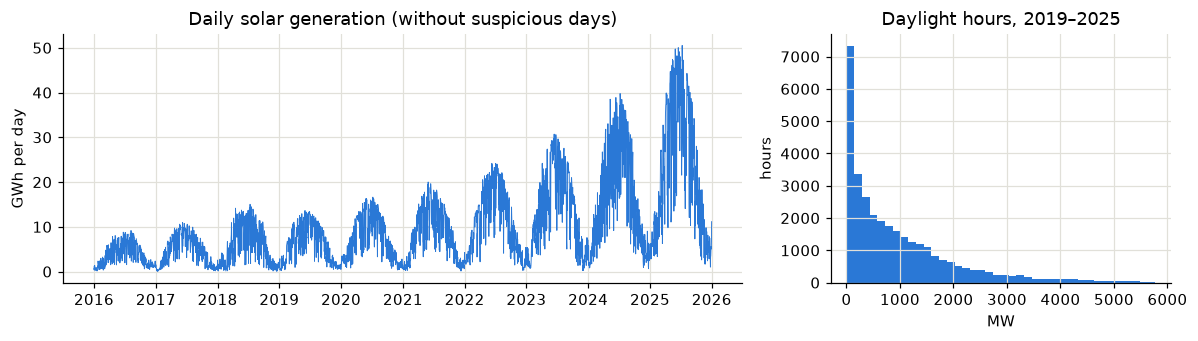

Hours with solar = 0, 2019-2025: 46 %
Highest hour per year (MW): {2019: 1584.0, 2020: 1880.0, 2021: 2283.0, 2022: 2783.0, 2023: 3552.0, 2024: 4661.0, 2025: 5773.0}


In [15]:
clean_daily = daily.loc["2016":"2025"].drop(suspicious.index, errors="ignore")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(clean_daily.index, clean_daily.values, color=BLUE, linewidth=0.6)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y", tz=TZ))
axes[0].set_ylabel("GWh per day")
axes[0].set_title("Daily solar generation (without suspicious days)")

hours = solar.loc["2019":"2025"]
axes[1].hist(hours[hours > 1], bins=40, color=BLUE)
axes[1].set_xlabel("MW")
axes[1].set_ylabel("hours")
axes[1].set_title("Daylight hours, 2019–2025")
plt.tight_layout()
save(fig, "series_and_distribution")
plt.show()
print(f"Hours with solar = 0, 2019-2025: {(hours == 0).mean() * 100:.0f} %")
print("Highest hour per year (MW):", solar.groupby(solar.index.year).max().round(0).loc[2019:2025].to_dict())

> **Finding:** generation **grows strongly** from year to year: the highest hour rises from 1,584 MW (2019) to 5,773 MW (2025). About 46 % of all hours are 0 (night), and the daylight hours are heavily skewed towards low values.
> **Consequence:** do not compare MW between years directly. Divide by the installed capacity (SFOE register, Flurin's notebook) to remove the growth. A mean over all hours says little, so we report medians or daylight values.

## Q11: Why is this dataset suitable for our goals?
Does it contain recurring patterns (daily, weekly, seasonal)? The course guide suggests a heatmap ("mosaic plot").

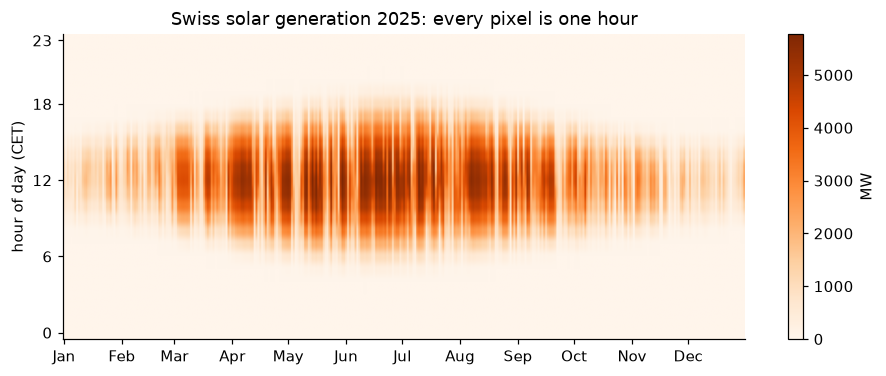

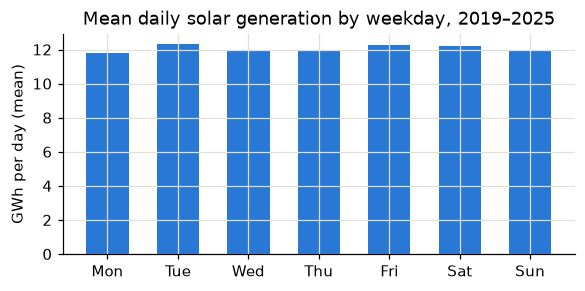

Difference between weekdays: 4.4 %
October to March: 26 % of the energy 2019-2025


In [16]:
# Heatmap ("mosaic plot"): one column per day, one row per hour, colour = solar MW
s = solar.loc["2025"]
mosaic = s.to_frame("MW").assign(day=s.index.dayofyear, hour=s.index.hour).pivot_table(index="hour", columns="day", values="MW")
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(mosaic, aspect="auto", origin="lower", cmap="Oranges", extent=[0.5, mosaic.shape[1] + 0.5, -0.5, 23.5])
ax.set_xticks([1, 32, 60, 91, 121, 152, 182, 213, 244, 274, 305, 335], ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks([0, 6, 12, 18, 23])
ax.set_ylabel("hour of day (CET)")
ax.set_title("Swiss solar generation 2025: every pixel is one hour")
ax.grid(False)
fig.colorbar(im, ax=ax, label="MW")
save(fig, "mosaic_2025")
plt.show()

# Weekly pattern? Mean daily energy per weekday
by_weekday = clean_daily.loc["2019":"2025"].groupby(clean_daily.loc["2019":"2025"].index.dayofweek).mean()
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(by_weekday.index, by_weekday.values, color=BLUE, width=0.6)
ax.set_ylabel("GWh per day (mean)")
ax.set_title("Mean daily solar generation by weekday, 2019–2025")
save(fig, "weekday")
plt.show()
print("Difference between weekdays:", round((by_weekday.max() / by_weekday.min() - 1) * 100, 1), "%")

# Share of October to March in the annual energy
monthly_energy = solar.loc["2019":"2025"].resample("MS").sum()
winter = monthly_energy[monthly_energy.index.month.isin([10, 11, 12, 1, 2, 3])].sum() / monthly_energy.sum() * 100
print(f"October to March: {winter:.0f} % of the energy 2019-2025")

> **Finding:**
> - The heatmap shows the patterns a forecast has to learn: a **daily cycle** (coloured only during daylight), a **seasonal cycle** (longer and stronger days in summer) and **day-to-day changes caused by the weather** (light stripes = cloudy days).
> - There is **no weekly pattern**: solar depends on the weather, not on human behaviour.
> - The winter half-year delivers only about a quarter of the energy.
> - The dataset is our target at the resolution of our forecast (hourly), has no missing hours in 2019–2025, matches the official annual totals and is openly licensed.
>
> **Consequence:** suitable as the target for G2 and G3, **but only partly**: it is national, not Lucerne, and its hourly shape is an extrapolation. We transfer it to Lucerne via the installed capacity and check that against measured data. The explanatory variable is the weather, not the calendar, which is Step 3.

## Q12: Leakage. Which columns will not exist at prediction time?

In [17]:
corr = df.loc["2019":"2025"].corrwith(solar.loc["2019":"2025"]).drop("Solar").dropna().sort_values(ascending=False).round(2)
corr.rename("correlation with Solar (Pearson r)").to_frame()

,correlation with Solar (Pearson r)
Renewable share of generation,0.35
Renewable share of load,0.25
Load,0.19
Hydro Run-of-River,0.10
Cross border electricity trading,0.01
Wind onshore,-0.05
Hydro water reservoir,-0.15
Hydro pumped storage,-0.17
Nuclear,-0.19
Others,-0.25


> **Finding:** all these columns are measured or calculated **at the same time** as the target. For a forecast made the day before, none of them is known. `Residual load` is even calculated from `Solar` (Q9).
> **Consequence:** do **not** use any of these columns as inputs. Allowed for the day-ahead forecast: past `Solar` values and weather *forecasts*. Measured weather of the same day is leakage too.

## Q13: Baseline. What would a very simple prediction score?

In [18]:
test = solar.loc["2025"]
train_mean = solar.loc["2019":"2024"].mean()
baseline = pd.Series({
    "constant: mean of 2019-2024": (test - train_mean).abs().mean() / test.mean() * 100,
    "same hour of the previous day": (solar.shift(24).loc["2025"] - test).abs().mean() / test.mean() * 100,
}).round(1)
print("Mean solar (MW), 2019-2024:", round(train_mean), "| 2025:", round(test.mean()))
baseline.rename("MAE in % of the mean, test year 2025").to_frame()

Mean solar (MW), 2019-2024: 433 | 2025: 907


,"MAE in % of the mean, test year 2025"
constant: mean of 2019-2024,106.2
same hour of the previous day,27.7


> **Finding:** a constant prediction is off by about **106 %** of the mean (it is also far too low, because the fleet has grown: 433 MW in 2019–2024 vs. 907 MW in 2025), "same hour as yesterday" by about **28 %** (hourly, raw MW; it assumes all of yesterday is known when the forecast is made).
> **Consequence:** these are the first yardsticks for G3. SARIMAX must clearly beat "same hour as yesterday"; the stricter yardstick with weather forecasts follows once they are loaded.

# Summary

## Decision log

| # | Issue | Error or characteristic? | Decision | Affected |
|---|---|---|---|---|
| Q2 | Duplicated time stamps at year boundaries | characteristic of our download | drop duplicates | 11 hours |
| Q3 | 2015–2016: gaps in several other sources | characteristic | not filled; columns not used | 2015, Nov 2016 |
| Q3/Q5 | 28.10.2017: 7 empty hours, rest of day 0 | **error** | whole day missing | 1 day |
| Q4 | 2015 only 19 % of the official total | **error** | drop 2015 | 1 year |
| Q5/Q5b | Suspicious days, mostly 2018 and 2019 | **error** (checked against measured sun) | set to NaN, not interpolated | 29 days |
| Q5b | 22.11.2024: very low output, 36 cm of snow | characteristic (real) | keep | 1 day |
| Q5b | 2018 fits the weather far worse, even without flagged days | **error** | leave out 2018, not approximated from radiation (circular, not needed); model on 2019–2025 | 1 year |
| Q6 | Clock changes in local time | characteristic | work in fixed CET (UTC+1) | all |
| Q7 | 415 MW at midnight (Sept 2022) | **error** | set to NaN | 2 hours |
| Q7 | Tiny values at night and after sunset (at most about 20 MW) | noise | negligible, unchanged | 0.004 % of the energy |
| Q8 | `Others` constant per year (2015–2024) | placeholder | column not used | – |
| Q9 | `Wind onshore` 11,000 MW | **error** | column not used | 1 hour |
| Q10 | Strong growth of the fleet | characteristic | divide by installed capacity | all |
| Q12 | `Residual load` and other columns known only afterwards | leakage risk | not used as inputs | – |

## Is the data suitable? (Insights)

**Only partly, but enough for our goals.** It is the right variable with the right resolution, with clear daily and seasonal patterns. Limits: it is national rather than Lucerne, its hourly shape is extrapolated, and 2018 cannot be used.

## Open questions (to discuss)

1. **Fixed CET (UTC+1) instead of clock time:** we chose it because it avoids the clock changes. Is that what was meant by "European time"?

## Next steps (Step 3 of the guide)

- Done: **MeteoSwiss** notebook (Elias). From Flurin: SFOE register and Open-Meteo forecasts.
- Combined notebook: **average radiation overlaid with the reported solar GW** (matplotlib).